# Machine Learning - Lab Assignment
## Linear Regression, Ridge and Lasso

Name: Righi Hadjer    Group: 1    Date: 10/11/2026

Use Python 3 and Jupyter Notebook. Required packages: `numpy`, `pandas`, `matplotlib`, and `scikit-learn`. If needed, install them with `pip install numpy pandas matplotlib scikit-learn`.

Work through the tasks in order. Create the dataset in Task 1; no external file is needed.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

### Task 1. Generate the dataset

Create a DataFrame named `df` with 500 synthetic salary records:

- Set the NumPy random seed to **42**.
- Generate 500 integers for `YearsOfExperience`, between **2 and 20 inclusive**, with `np.random.randint(2, 21, size=500)`.
- Set `intercept = 60000` and `slope = (200000 - 60000) / (20 - 2)`.
- Generate 500 noise values from a normal distribution using `np.random.normal(0, 10000, size=500)`.
- Compute `Salary = intercept + slope * YearsOfExperience + noise`.
- Use pandas to create `df` with exactly two columns: `YearsOfExperience` and `Salary`. Display its first five rows and check that its shape is `(500, 2)`.

Generate the experience values **before** generating the noise. Do not load a dataset from a file.

In [3]:
# Task 1: Generate the dataset
np.random.seed(42)

YearsOfExperience = np.random.randint(2, 21, size=500)

intercept = 60000
slope = (200000 - 60000) / (20 - 2)

noise = np.random.normal(0, 10000, size=500)

Salary = intercept + slope * YearsOfExperience + noise

df = pd.DataFrame({
    "YearsOfExperience": YearsOfExperience,
    "Salary": Salary
})

display(df.head())
print("Shape:", df.shape)

,YearsOfExperience,Salary
0,8,115037.780010
1,16,182309.972927
2,12,156442.408989
3,9,144753.562169
4,8,130798.818454


Shape: (500, 2)


### Task 2. Explore the dataset

Display the dataset shape, summary statistics and number of missing values in each column. Calculate the correlation between `YearsOfExperience` and `Salary`.

In [ ]:
# Task 2: Explore the dataset
print("Shape:", df.shape)

print("\nSummary statistics:")
display(df.describe())

print("\nMissing values:")
display(df.isnull().sum())

correlation = df["YearsOfExperience"].corr(df["Salary"])
print("\nCorrelation:", correlation)

Shape: (500, 2)
\nSummary statistics:


,YearsOfExperience,Salary
count,500.000000,500.000000
mean,10.616000,142570.011096
std,5.662922,44935.263058
min,2.000000,54881.134555
25%,5.750000,104426.300731
50%,10.000000,139865.032545
75%,16.000000,182341.125962
max,20.000000,241879.376204


\nMissing values:


YearsOfExperience    0
Salary               0
dtype: int64

\nCorrelation: 0.975058457607618


### Task 3. Plot the data

Draw a scatter plot with `YearsOfExperience` on the x-axis and `Salary` on the y-axis. Add axis labels and a title.

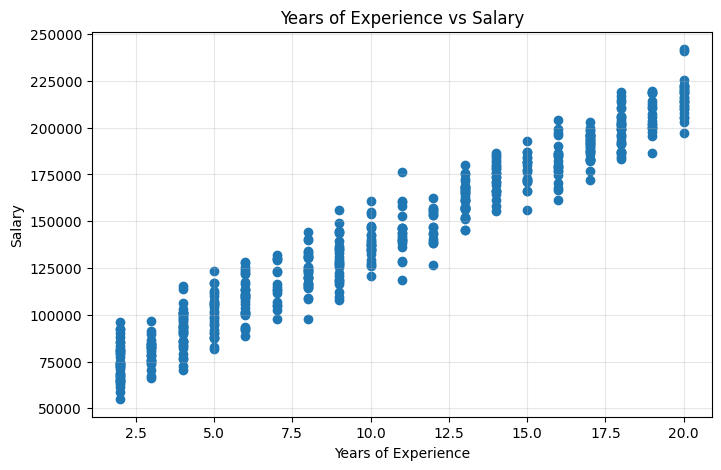

In [ ]:
# Task 3: Plot the data
plt.figure(figsize=(8, 5))
plt.scatter(df["YearsOfExperience"], df["Salary"])
plt.xlabel("Years of Experience")
plt.ylabel("Salary")
plt.title("Years of Experience vs Salary")
plt.grid(True, alpha=0.3)
plt.show()

### Task 4. Split the dataset

Set `X` to the `YearsOfExperience` column as a two-dimensional DataFrame and `y` to `Salary`. Use `train_test_split` with `test_size=0.20` and `random_state=42`. Display the number of training and test records.

In [ ]:
# Task 4: Split the dataset
X = df[["YearsOfExperience"]]
y = df["Salary"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print("Training records:", len(X_train))
print("Test records:", len(X_test))

Training records: 400
Test records: 100


### Task 5. Train linear regression

Fit a `LinearRegression` model on the training data. Display the slope, intercept, training R2 and test R2.

In [ ]:
# Task 5: Train linear regression
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

print("Slope:", lr_model.coef_[0])
print("Intercept:", lr_model.intercept_)
print("Training R2:", lr_model.score(X_train, y_train))
print("Test R2:", lr_model.score(X_test, y_test))

Slope: 7696.612923052044
Intercept: 60961.340880280564
Training R2: 0.9488372177019488
Test R2: 0.9573704756930141


### Task 6. Evaluate linear regression

Predict salary for the test set. Calculate MAE, MSE, RMSE and R2. Display the first five actual and predicted salaries in a table.

In [ ]:
# Task 6: Evaluate linear regression
y_pred = lr_model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2:", r2)

evaluation_table = pd.DataFrame({
    "Actual Salary": y_test.values,
    "Predicted Salary": y_pred
})
display(evaluation_table.head())

MAE: 7905.114728709239
MSE: 93933277.37947103
RMSE: 9691.918147584152
R2: 0.9573704756930141


,Actual Salary,Predicted Salary
0,123631.230350,107141.018419
1,139775.630647,122534.244265
2,93184.812446,107141.018419
3,166740.803478,161017.308880
4,174587.183981,184107.147649


### Task 7. Compare with a baseline

Use the mean of `y_train` as the predicted salary for every test record. Compute baseline MAE and RMSE and compare them with linear regression.

In [ ]:
# Task 7: Compare with a baseline
baseline_pred = np.full(len(y_test), y_train.mean())

baseline_mae = mean_absolute_error(y_test, baseline_pred)
baseline_rmse = np.sqrt(mean_squared_error(y_test, baseline_pred))

print("Baseline MAE:", baseline_mae)
print("Baseline RMSE:", baseline_rmse)
print("Linear Regression MAE:", mae)
print("Linear Regression RMSE:", rmse)

Baseline MAE: 40444.95787424255
Baseline RMSE: 46953.769510036946
Linear Regression MAE: 7905.114728709239
Linear Regression RMSE: 9691.918147584152


### Task 8. Plot predictions and residuals

Make two graphs: (a) test observations and the fitted regression line; (b) residuals (`actual - predicted`) against years of experience, with a horizontal line at zero.

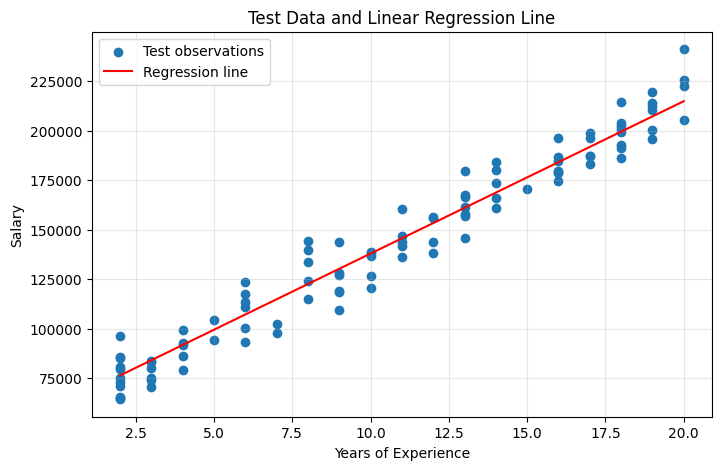

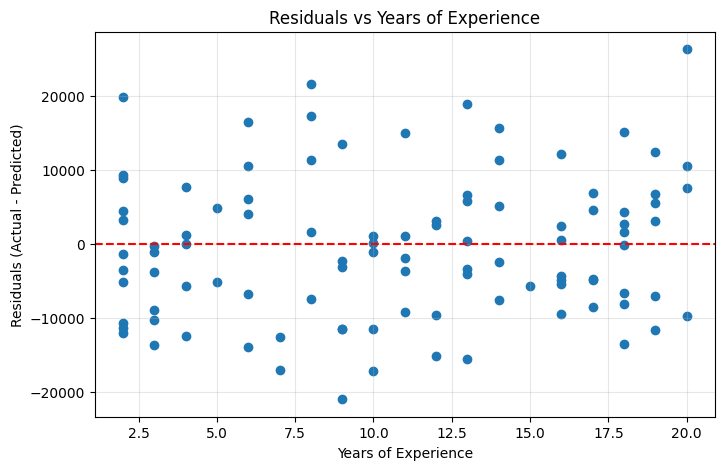

In [ ]:
# Task 8: Plot predictions and residuals

# (a) Test observations and fitted regression line
plt.figure(figsize=(8, 5))
plt.scatter(X_test["YearsOfExperience"], y_test, label="Test observations")

sorted_indices = np.argsort(X_test["YearsOfExperience"].to_numpy())
x_sorted = X_test["YearsOfExperience"].to_numpy()[sorted_indices]
pred_sorted = y_pred[sorted_indices]

plt.plot(x_sorted, pred_sorted, color="red", label="Regression line")
plt.xlabel("Years of Experience")
plt.ylabel("Salary")
plt.title("Test Data and Linear Regression Line")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# (b) Residuals
residuals = y_test.to_numpy() - y_pred

plt.figure(figsize=(8, 5))
plt.scatter(X_test["YearsOfExperience"], residuals)
plt.axhline(y=0, color="red", linestyle="--")
plt.xlabel("Years of Experience")
plt.ylabel("Residuals (Actual - Predicted)")
plt.title("Residuals vs Years of Experience")
plt.grid(True, alpha=0.3)
plt.show()

### Task 9. Predict new salaries

Use the linear regression model to predict salaries for **5, 10 and 15 years** of experience. Display the results in a table.

In [ ]:
# Task 9: Predict new salaries
new_data = pd.DataFrame({
    "YearsOfExperience": [5, 10, 15]
})

new_salary_predictions = lr_model.predict(new_data)

prediction_table = pd.DataFrame({
    "YearsOfExperience": [5, 10, 15],
    "Predicted Salary": new_salary_predictions
})

display(prediction_table)

,YearsOfExperience,Predicted Salary
0,5,99444.405496
1,10,137927.470111
2,15,176410.534726


### Task 10. Standardize the feature

Use `StandardScaler` on `X_train` and `X_test`. Fit the scaler on the training set only, then transform both sets. Keep the target `y` unchanged.

In [ ]:
# Task 10: Standardize the feature
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("First five scaled training values:")
print(X_train_scaled[:5])

print("\nFirst five scaled test values:")
print(X_test_scaled[:5])

First five scaled training values:
[[ 1.14441709]
 [-0.45865743]
 [ 0.07570074]
 [-1.52737378]
 [-1.171135  ]]
\nFirst five scaled test values:
[[-0.81489621]
 [-0.45865743]
 [-0.81489621]
 [ 0.43193952]
 [ 0.9662977 ]]


### Task 11. Train Ridge regression

Fit two `Ridge` models on the scaled training set, using `alpha=10` and `alpha=100`. For each model, display its coefficient, test MAE and test R2. Compare the coefficients. Keep the `alpha=10` model for Task 13.

In [ ]:
# Task 11: Train Ridge regression
ridge10 = Ridge(alpha=10)
ridge100 = Ridge(alpha=100)

ridge10.fit(X_train_scaled, y_train)
ridge100.fit(X_train_scaled, y_train)

ridge10_pred = ridge10.predict(X_test_scaled)
ridge100_pred = ridge100.predict(X_test_scaled)

ridge_results = pd.DataFrame({
    "Alpha": [10, 100],
    "Coefficient": [ridge10.coef_[0], ridge100.coef_[0]],
    "Test MAE": [
        mean_absolute_error(y_test, ridge10_pred),
        mean_absolute_error(y_test, ridge100_pred)
    ],
    "Test R2": [
        r2_score(y_test, ridge10_pred),
        r2_score(y_test, ridge100_pred)
    ]
})

display(ridge_results)

,Alpha,Coefficient,Test MAE,Test R2
0,10,42156.503108,8084.461348,0.955727
1,100,34568.332548,11308.369994,0.911838


### Task 12. Train Lasso regression

Fit three `Lasso` models on the scaled training set, using `alpha=1000`, `alpha=10000` and `alpha=50000`. Set `max_iter=20000`. For each model, display its coefficient, test MAE and test R2. Observe what happens to the coefficient as alpha increases. Keep the `alpha=1000` model for Task 13.

In [ ]:
# Task 12: Train Lasso regression
lasso1000 = Lasso(alpha=1000, max_iter=20000)
lasso10000 = Lasso(alpha=10000, max_iter=20000)
lasso50000 = Lasso(alpha=50000, max_iter=20000)

lasso1000.fit(X_train_scaled, y_train)
lasso10000.fit(X_train_scaled, y_train)
lasso50000.fit(X_train_scaled, y_train)

lasso1000_pred = lasso1000.predict(X_test_scaled)
lasso10000_pred = lasso10000.predict(X_test_scaled)
lasso50000_pred = lasso50000.predict(X_test_scaled)

lasso_results = pd.DataFrame({
    "Alpha": [1000, 10000, 50000],
    "Coefficient": [
        lasso1000.coef_[0],
        lasso10000.coef_[0],
        lasso50000.coef_[0]
    ],
    "Test MAE": [
        mean_absolute_error(y_test, lasso1000_pred),
        mean_absolute_error(y_test, lasso10000_pred),
        mean_absolute_error(y_test, lasso50000_pred)
    ],
    "Test R2": [
        r2_score(y_test, lasso1000_pred),
        r2_score(y_test, lasso10000_pred),
        r2_score(y_test, lasso50000_pred)
    ]
})

display(lasso_results)
print("As alpha increases, the Lasso coefficient is pushed toward zero.")

,Alpha,Coefficient,Test MAE,Test R2
0,1000,42210.415685,8074.651463,0.955838
1,10000,33210.415685,12287.962687,0.898045
2,50000,0.000000,40444.957874,-0.000534


As alpha increases, the Lasso coefficient is pushed toward zero.


### Task 13. Compare the models

Create a table showing test MAE, RMSE and R2 for: the mean baseline, linear regression, Ridge (`alpha=10`) and Lasso (`alpha=1000`). Write two sentences about the results.

In [ ]:
# Task 13: Compare the models
baseline_pred = np.full(len(y_test), y_train.mean())

models = {
    "Mean Baseline": baseline_pred,
    "Linear Regression": y_pred,
    "Ridge (alpha=10)": ridge10_pred,
    "Lasso (alpha=1000)": lasso1000_pred
}

comparison_rows = []

for model_name, predictions in models.items():
    comparison_rows.append({
        "Model": model_name,
        "Test MAE": mean_absolute_error(y_test, predictions),
        "Test RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "Test R2": r2_score(y_test, predictions)
    })

comparison_df = pd.DataFrame(comparison_rows)
display(comparison_df)

,Model,Test MAE,Test RMSE,Test R2
0,Mean Baseline,40444.957874,46953.769510,-0.000534
1,Linear Regression,7905.114729,9691.918148,0.957370
2,Ridge (alpha=10),8084.461348,9876.931577,0.955727
3,Lasso (alpha=1000),8074.651463,9864.608230,0.955838


**Task 13 – Short comparison Linear Regression performs much better than the Mean Baseline because it has lower test MAE and RMSE and a higher R2 score. Ridge (`alpha=10`) and Lasso (`alpha=1000`) give results close to Linear Regression, while increasing Lasso's alpha pushes its coefficient toward zero.

**Submission:** Save the notebook with your code, results and plots. Include your short comparison for Task 13.